Kernel: `pippe` (pixi env; register with `pixi run kernel`)

# Global runoff ratio

Global-mean annual runoff ratio (R/P) for every member, and each member's anomaly from the default run.

In [1]:
import re
import numpy as np
import matplotlib.pyplot as plt

import pippe.config as config
import pippe.load as load

In [2]:
GLC_THRESH = 1.0           # mask gridcells with >=GLC_TRESH glaciated area
LAT_BNDS = slice(-90, 90)  # mask Antarctica


def convert_to_mm_day(da):
    """Convert [mm/s, m/s] to mm/day"""
    units = re.split(r'[/\s]+', da.attrs["units"])

    assert units[1] == "s"
    da = da * 86400

    if units[0] == "m":
        da = da * 1000
    
    da.attrs["units"] = "mm/day"
    return da


def annual_mean(da):
    """Calendar-year means of monthly data, weighted by days per month."""
    days = da["time"].dt.days_in_month
    weights = days.groupby("time.year") / days.groupby("time.year").sum()
    return (da * weights).groupby("time.year").sum("time", min_count=1)


def global_mean(da, weights):
    """Area-weighted mean over lat/lon."""
    return da.weighted(weights.fillna(0)).mean(("lat", "lon"))


def anomaly(ens, ref=config.DEFAULT_KEY):
    """Each member minus the reference member (the default run unless given)."""
    return ens - ens.sel(member=ref).reset_coords(drop=True)

In [3]:
grid = load.open_grid()

In [4]:
pct_glc = load.open_ensemble("PCT_LANDUNIT", gcomp="lnd", freq="month_1")

# Store member, param, minmax for later
member = pct_glc["member"]

# Mask glaciated land
glc_mask = (pct_glc.isel(member=0, time=0, ltype=3) / 100) <= GLC_THRESH

In [5]:
# Load total ET
et = load.open_ensemble("EFLX_LH_TOT", gcomp="lnd", freq="month_1").where(glc_mask).sel(lat=LAT_BNDS)

In [6]:
# Compute total precip from convective + large-scale
prc = load.open_ensemble("PRECC", gcomp="atm", freq="month_1").where(glc_mask).sel(lat=LAT_BNDS)
prl = load.open_ensemble("PRECL", gcomp="atm", freq="month_1").where(glc_mask).sel(lat=LAT_BNDS)
pr = prc + prl

pr = convert_to_mm_day(pr)

In [7]:
# Load surface runoff (QOVER) and total runoff including subsurface (QRUNOFF)
qover = load.open_ensemble("QOVER", gcomp="lnd", freq="month_1").where(glc_mask).sel(lat=LAT_BNDS)
qrunoff = load.open_ensemble("QRUNOFF", gcomp="lnd", freq="month_1").where(glc_mask).sel(lat=LAT_BNDS)

qover = convert_to_mm_day(qover)
qrunoff = convert_to_mm_day(qrunoff)

Text(0.5, 1.0, 'glaciated land mask')

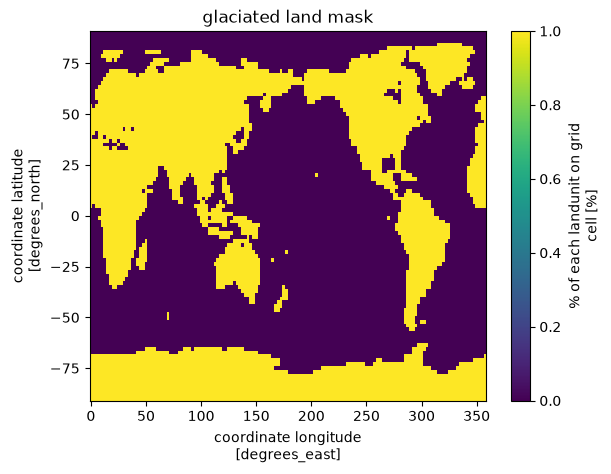

In [8]:
glc_mask.sel(lat=LAT_BNDS).plot()
plt.title("glaciated land mask")

In [9]:
pr_tm = annual_mean(pr).mean(dim="year").compute()
qover_tm = annual_mean(qover).mean(dim="year").compute()
qrunoff_tm = annual_mean(qrunoff).mean(dim="year").compute()
et_tm = annual_mean(et).mean(dim="year").compute()

In [108]:
pr_tm_zm = pr_tm.mean(dim="lon")
qover_tm_zm = qover_tm.mean(dim="lon")
qrunoff_tm_zm = qrunoff_tm.mean(dim="lon")
et_tm_zm = et_tm.mean(dim="lon")

qover_ratio_tm_zm = qover_tm_zm / pr_tm_zm
qrunoff_ratio_tm_zm = qrunoff_tm_zm / pr_tm_zm

pr_tm_zm_anom = anomaly(pr_tm_zm)
qover_tm_zm_anom = anomaly(qover_tm_zm)
qrunoff_tm_zm_anom = anomaly(qrunoff_tm_zm)
et_tm_zm_anom = anomaly(et_tm_zm)
qover_ratio_tm_zm_anom = anomaly(qover_ratio_tm_zm)
qrunoff_ratio_tm_zm_anom = anomaly(qrunoff_ratio_tm_zm)

pr_tm_zm_anom = pr_tm_zm_anom.assign_coords(member.coords)
qover_tm_zm_anom = qover_tm_zm_anom.assign_coords(member.coords)
qrunoff_tm_zm_anom = qrunoff_tm_zm_anom.assign_coords(member.coords)
et_tm_zm_anom = et_tm_zm_anom.assign_coords(member.coords)
qover_ratio_tm_zm_anom = qover_ratio_tm_zm_anom.assign_coords(member.coords)
qrunoff_ratio_tm_zm_anom = qrunoff_ratio_tm_zm_anom.assign_coords(member.coords)

In [10]:
weights = grid["area"] * grid["landfrac"]

pr_tm_gm = global_mean(pr_tm, weights)
qover_tm_gm = global_mean(qover_tm, weights)
qrunoff_tm_gm = global_mean(qrunoff_tm, weights)
et_tm_gm = global_mean(et_tm, weights)

qover_ratio_tm_gm = qover_tm_gm / pr_tm_gm
qrunoff_ratio_tm_gm = qrunoff_tm_gm / pr_tm_gm

pr_tm_gm_anom = anomaly(pr_tm_gm)
qover_tm_gm_anom = anomaly(qover_tm_gm)
qrunoff_tm_gm_anom = anomaly(qrunoff_tm_gm)
et_tm_gm_anom = anomaly(et_tm_gm)
qover_ratio_tm_gm_anom = anomaly(qover_ratio_tm_gm)
qrunoff_ratio_tm_gm_anom = anomaly(qrunoff_ratio_tm_gm)

pr_tm_gm_anom = pr_tm_gm_anom.assign_coords(member.coords)
qover_tm_gm_anom = qover_tm_gm_anom.assign_coords(member.coords)
qrunoff_tm_gm_anom = qrunoff_tm_gm_anom.assign_coords(member.coords)
et_tm_gm_anom = et_tm_gm_anom.assign_coords(member.coords)
qover_ratio_tm_gm_anom = qover_ratio_tm_gm_anom.assign_coords(member.coords)
qrunoff_ratio_tm_gm_anom = qrunoff_ratio_tm_gm_anom.assign_coords(member.coords)

## Parameter range bar plots

In [ ]:
def plot_param_anom_range_bars(da, label, ylim=[None, None], save:str|None=None):
    """Plot bars spanning the min/max for each parameter."""
    ps = [p for sublist in config.PARAM_COLORS.values() for p in sublist]
    colors = {p: color for color, params in config.PARAM_COLORS.items() for p in params}
    xs = np.arange(0, len(ps))

    fig, ax = plt.subplots(layout="constrained", figsize=(9, 7))
    ax.grid(lw=0.5)
    ax.set_axisbelow(True)

    for x, p in zip(xs, ps):
        pair = da.sel(param=p)
        bot = pair.min(dim="member")
        hgt = pair.max(dim="member") - bot
        ax.bar(x, height=hgt, bottom=bot, width=0.5, color=colors[p])

    ax.set_ylim(ylim[0], ylim[1])
    ax.axhline(0, lw=0.8, c="k", ls="--", zorder=0)
    ax.axvline(7.5, lw=0.8, c="k", ls="-", zorder=0)
    ax.set_ylabel(label, fontsize=12)
    ax.set_xticks(xs)
    ax.set_xticklabels(ps, rotation=90, fontsize=10)
    plt.show()

    if save:
        fig.savefig(config.FIG_DIR / save, dpi=300)

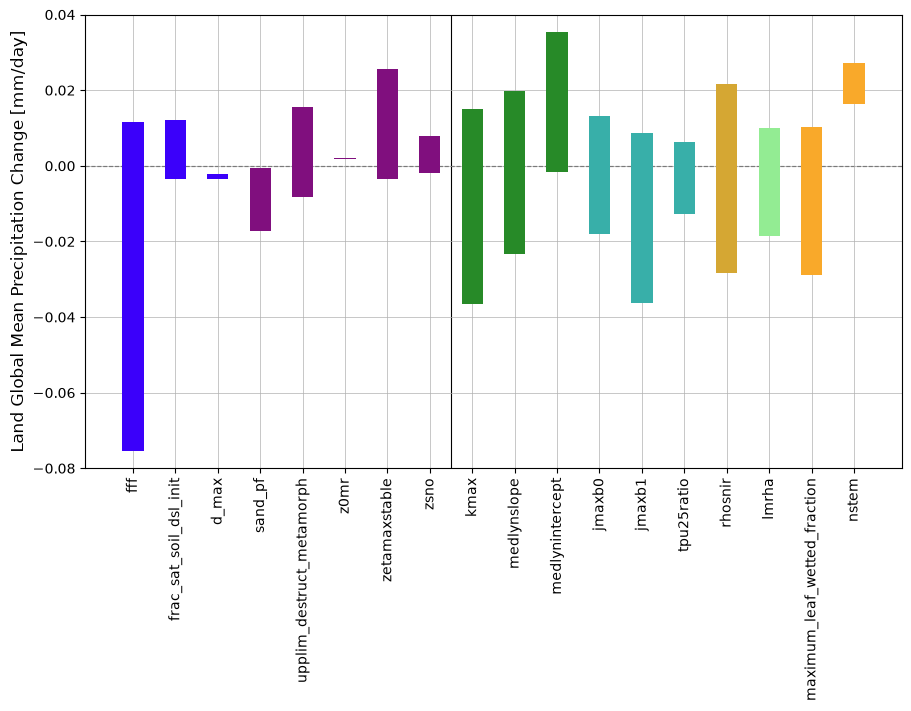

In [18]:
plot_param_anom_range_bars(
    pr_tm_gm_anom,
    "Land Global Mean Precipitation Change [mm/day]",
    ylim=[-0.08, 0.04],
    save=config.FIG_DIR / "param_anom_range_pr.png",
)

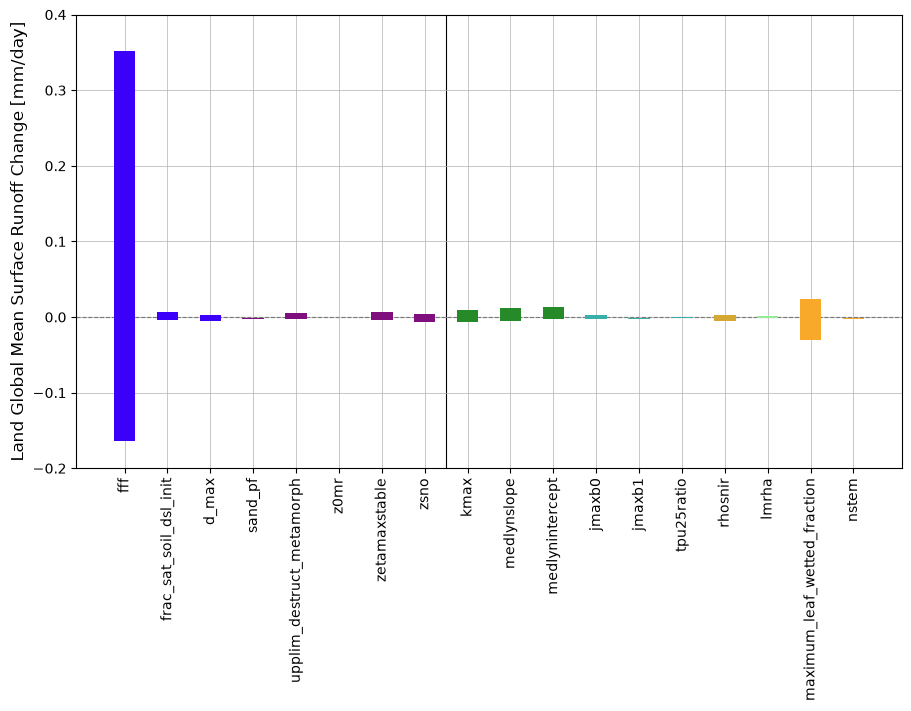

In [19]:
plot_param_anom_range_bars(
    qover_tm_gm_anom,
    "Land Global Mean Surface Runoff Change [mm/day]",
    ylim=[-0.2, 0.4],
    save=config.FIG_DIR / "param_anom_range_qover.png",
)

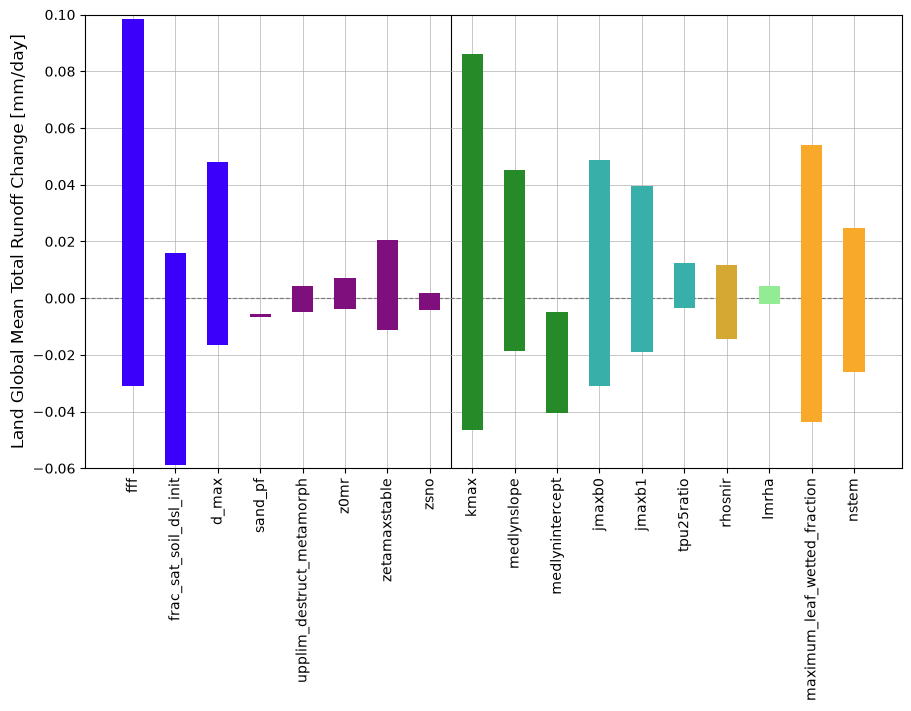

In [20]:
plot_param_anom_range_bars(
    qrunoff_tm_gm_anom,
    "Land Global Mean Total Runoff Change [mm/day]",
    ylim=[-0.06, 0.1],
    save=config.FIG_DIR / "param_anom_range_qrunoff.png",
)

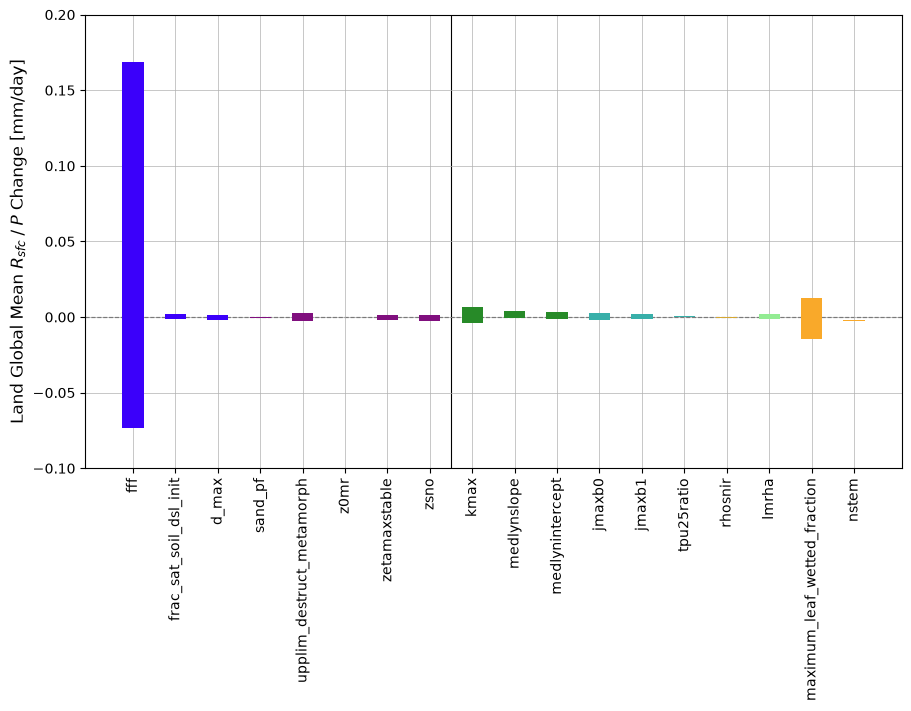

In [23]:
plot_param_anom_range_bars(
    qover_ratio_tm_gm_anom,
    "Land Global Mean $R_{sfc} \\; / \\; P$ Change [mm/day]",
    ylim=[-0.1, 0.2],
    save=config.FIG_DIR / "param_anom_range_qover_ratio.png",
)

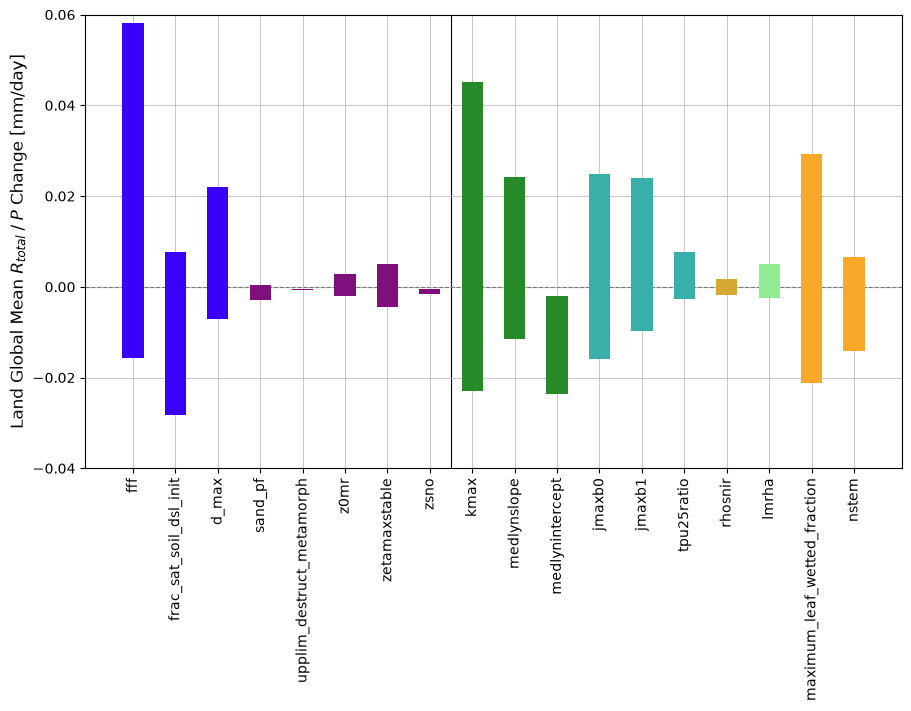

In [24]:
plot_param_anom_range_bars(
    qrunoff_ratio_tm_gm_anom,
    "Land Global Mean $R_{total} \\; / \\; P$ Change [mm/day]",
    ylim=[-0.04, 0.06],
    save=config.FIG_DIR / "param_anom_range_qrunoff_ratio.png",
)

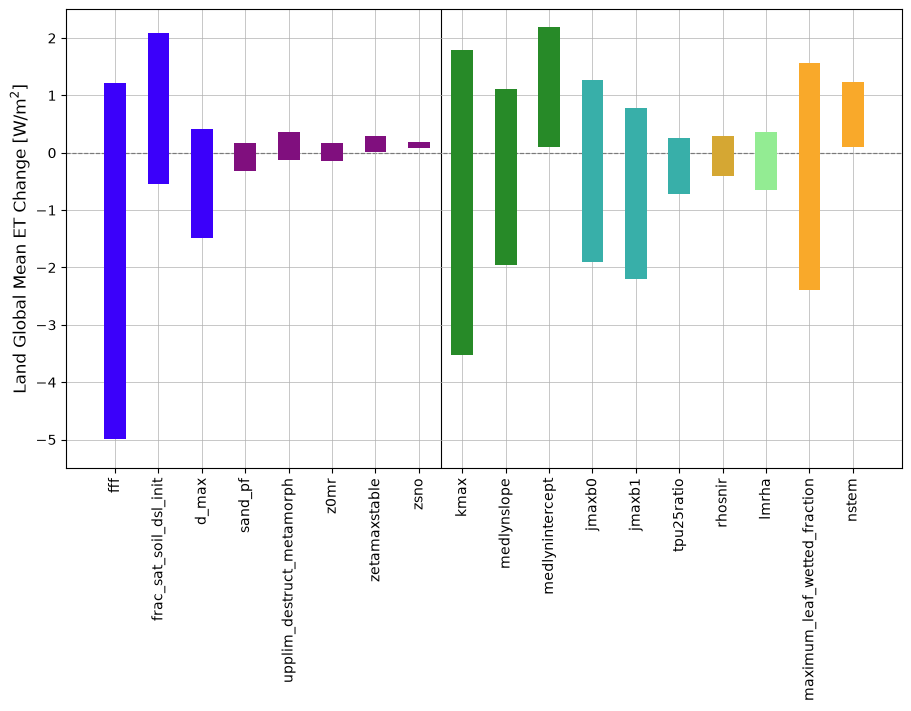

In [25]:
plot_param_anom_range_bars(
    et_tm_gm_anom,
    "Land Global Mean ET Change [W/m$^2$]",
    ylim=[-5.5, 2.5],
    save=config.FIG_DIR / "param_anom_range_et.png",
)

## Zonal mean plots

In [33]:
PARAM_COLORS = {
    "#3B00FA": ["fff", "frac_sat_soil_dsl_init", "d_max"],
    "#800F7E": ["sand_pf", "upplim_destruct_metamorph", "z0mr", "zetamaxstable", "zsno"],
    "#278A28": ["kmax", "medlynslope", "medlynintercept"],
    "#38AFA9": ["jmaxb0", "jmaxb1", "tpu25ratio"],
    "#D5A733": ["rhosnir"],
    "#93EC93": ["lmrha"],
    "#F9A92A": ["maximum_leaf_wetted_fraction", "nstem"],
}

In [99]:
def zonal_mean_spaghetti_plot(da, label, ylim=[None, None], use_colors=False, save:str|None=None):
    """Plot the zonal mean for each member on the same plot."""
    ps = [p for sublist in PARAM_COLORS.values() for p in sublist]

    if use_colors:
        colors = {p: color for color, params in PARAM_COLORS.items() for p in params}
    else:
        colors = {p: "gray" for p in ps}

    fig, ax = plt.subplots(layout="constrained", figsize=(9, 5))
    ax.grid(lw=0.5)
    ax.set_axisbelow(True)

    for i, p in enumerate(ps):
        for da_mm, ls, line_label in zip(da.sel(param=p), ["--", "-"], ["Minimum perturbation", "Maximum perturbation"]):
            ax.plot(da_mm.lat, da_mm, ls=ls, lw=0.8, color=colors[p], label=line_label if i == 0 else "_nolegend_")

    ax.axhline(0, lw=2, c="k", ls="-", zorder=0)
    ax.legend()
    ax.set_ylim(ylim[0], ylim[1])
    ax.set_xlim(-90, 90)
    ax.set_ylabel(label, fontsize=12)
    ax.set_xlabel("Latitude [\u00b0N]", fontsize=12)
    plt.show()

    if save:
        fig.savefig(config.FIG_DIR / save, dpi=300)

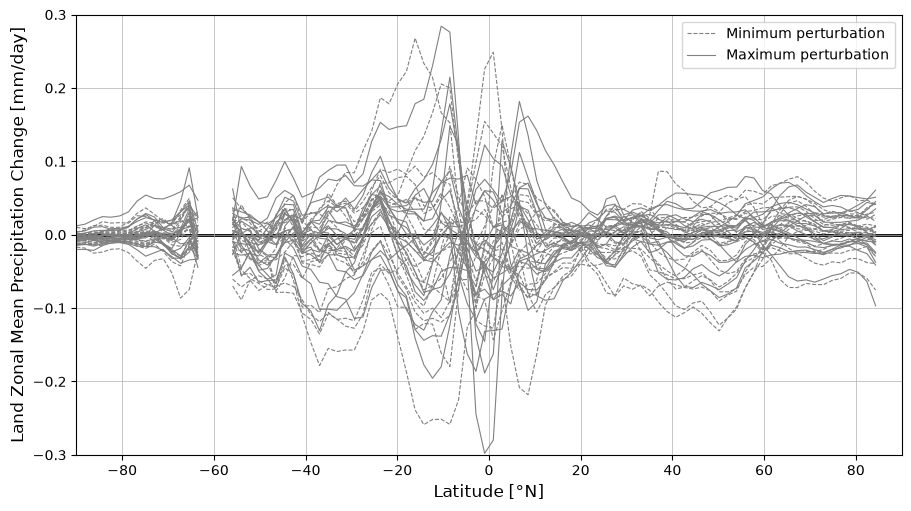

In [101]:
zonal_mean_spaghetti_plot(
    pr_tm_zm_anom,
    "Land Zonal Mean Precipitation Change [mm/day]",
    ylim=[-0.3, 0.3],
    save=config.FIG_DIR / "zonal_mean_lines_pr.png",
)

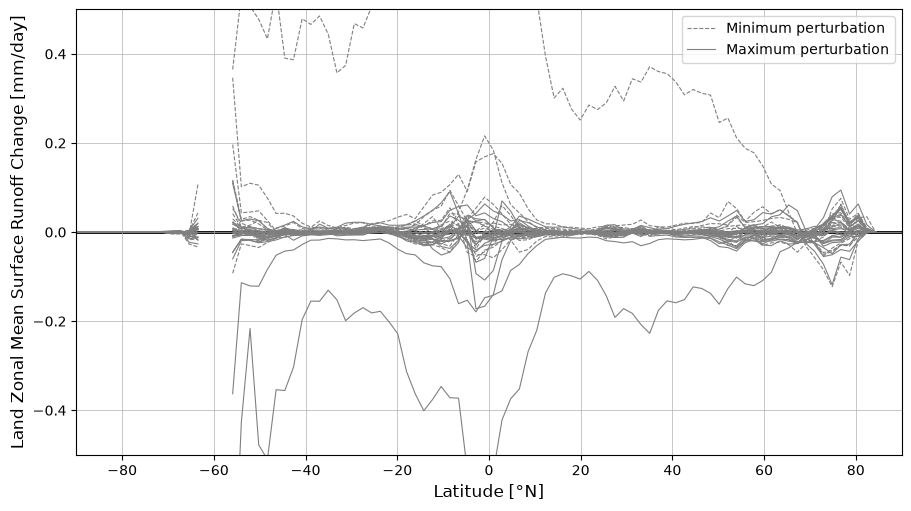

In [104]:
zonal_mean_spaghetti_plot(
    qover_tm_zm_anom,
    "Land Zonal Mean Surface Runoff Change [mm/day]",
    ylim=[-0.5, 0.5],
    save=config.FIG_DIR / "zonal_mean_lines_qover.png",
)

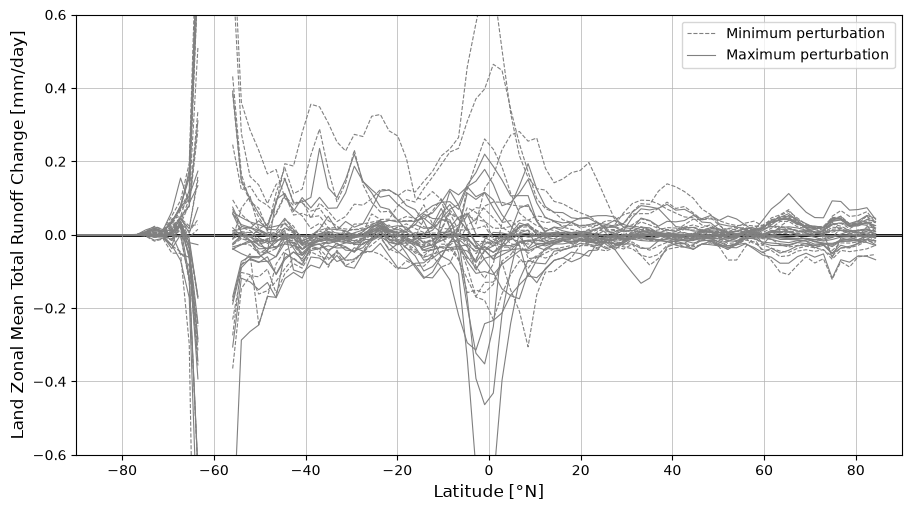

In [114]:
zonal_mean_spaghetti_plot(
    qrunoff_tm_zm_anom,
    "Land Zonal Mean Total Runoff Change [mm/day]",
    ylim=[-0.6, 0.6],
    save=config.FIG_DIR / "zonal_mean_lines_qrunoff.png",
)

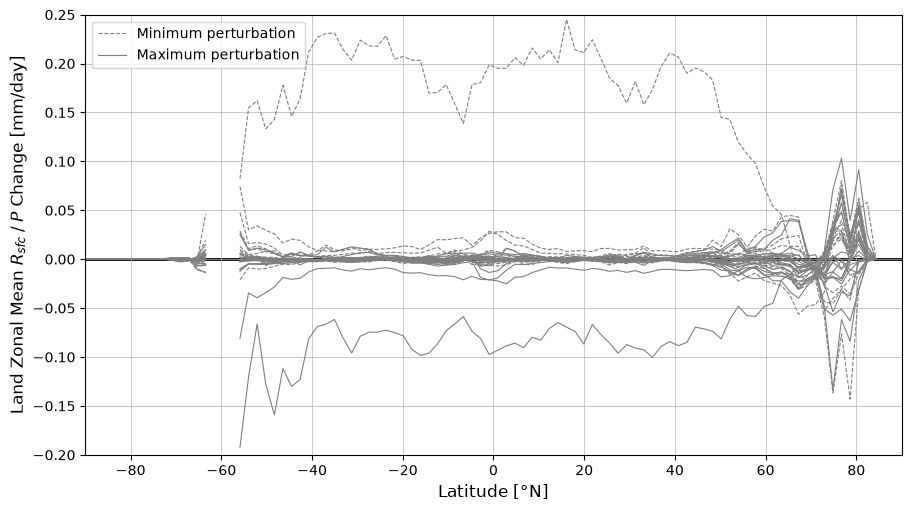

In [112]:
zonal_mean_spaghetti_plot(
    qover_ratio_tm_zm_anom,
    "Land Zonal Mean $R_{sfc} \\; / \\; P$ Change [mm/day]",
    ylim=[-0.2, 0.25],
    save=config.FIG_DIR / "zonal_mean_lines_qover_ratio.png",
)

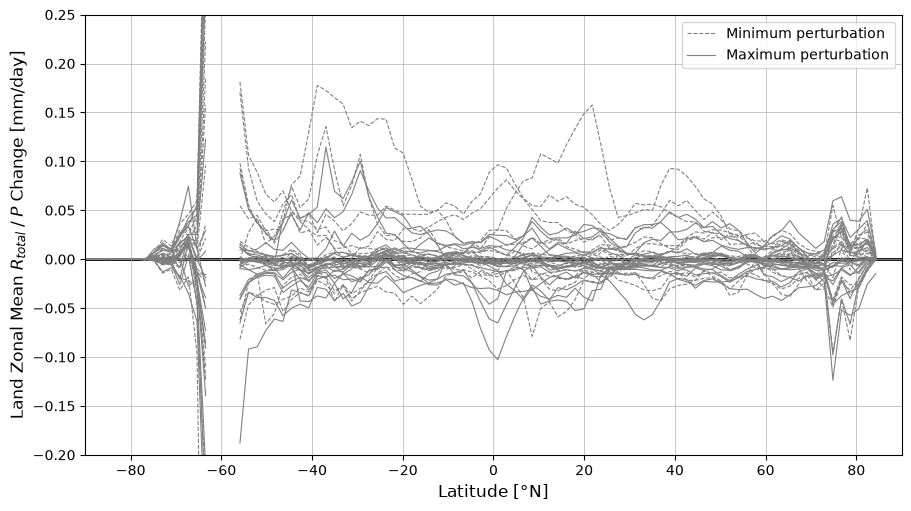

In [115]:
zonal_mean_spaghetti_plot(
    qrunoff_ratio_tm_zm_anom,
    "Land Zonal Mean $R_{total} \\; / \\; P$ Change [mm/day]",
    ylim=[-0.2, 0.25],
    save=config.FIG_DIR / "zonal_mean_lines_qrunoff_ratio.png",
)

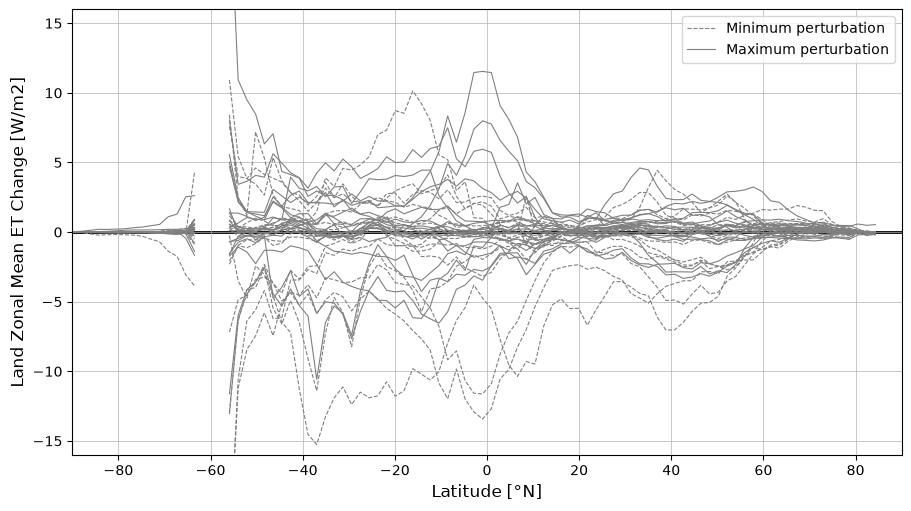

In [130]:
zonal_mean_spaghetti_plot(
    et_tm_zm_anom,
    "Land Zonal Mean ET Change [W/m2]",
    ylim=[-16, 16],
    save=config.FIG_DIR / "zonal_mean_lines_et.png",
)